# Pipeline — LightGBM → Feature Engineering → CatBoost + Blend

Un seul notebook, 3 étapes, 3 soumissions :

| Étape | Contenu | Fichier |
|---|---|---|
| 1 | LightGBM, features brutes, catégories natives | `submission_1_lgb_raw.csv` |
| 2 | LightGBM + FE (ablation par groupe, target encoding **par fold**) | `submission_2_lgb_fe.csv` |
| 3 | CatBoost sur les mêmes features + blend avec LightGBM | `submission_3_blend.csv` |

Prédiction test = moyenne des 5 modèles de la CV.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
TARGET = 'TotalKg'
y = train[TARGET].values

FOLDS = list(KFold(n_splits=5, shuffle=True, random_state=42).split(train))
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_CAT = [c for c in test.columns if test[c].dtype == 'object']

results = {}  # nom -> (oof, pred_test, rmse)

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

def save(name, pred):
    pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(name, index=False)
    print('Sauvegardé :', name)

print('Train:', train.shape, '| Test:', test.shape)
print('Catégorielles:', RAW_CAT)

Train: (105000, 18) | Test: (45000, 17)
Catégorielles: ['Sex', 'Equipment', 'AgeClass', 'BirthYearClass', 'WeightClassKg', 'Tested', 'Country', 'State', 'Federation', 'ParentFederation', 'MeetCountry', 'MeetState', 'Sanctioned']


## Outils : CV générique + target encoding sans fuite

In [2]:
def make_X(tr_df, te_df, feats, cats):
    """Catégories construites sur train+test pour avoir les mêmes modalités."""
    full = pd.concat([tr_df[feats], te_df[feats]], axis=0, ignore_index=True)
    for c in cats:
        full[c] = full[c].astype('category')
    return full.iloc[:len(tr_df)].reset_index(drop=True), full.iloc[len(tr_df):].reset_index(drop=True)


def te_fold(keys_tr, y_tr, keys_others, smoothing=20, n_inner=5):
    """Target encoding lissé. Lignes d'entraînement encodées en out-of-fold interne
    (pas de fuite), val/test encodés avec toutes les lignes d'entraînement du fold."""
    prior = y_tr.mean()

    def fit_map(k, yy):
        g = pd.DataFrame({'k': k, 'y': yy}).groupby('k')['y'].agg(['sum', 'count'])
        return (g['sum'] + smoothing * prior) / (g['count'] + smoothing)

    enc_tr = np.empty(len(keys_tr))
    for a, b in KFold(n_inner, shuffle=True, random_state=0).split(keys_tr):
        enc_tr[b] = pd.Series(keys_tr[b]).map(fit_map(keys_tr[a], y_tr[a])).fillna(prior).values
    full_map = fit_map(keys_tr, y_tr)
    return enc_tr, [pd.Series(k).map(full_map).fillna(prior).values for k in keys_others]


def cv_model(fit_predict, X, X_test, te_specs=(), name=''):
    """te_specs : liste de (nom_colonne, clés_train, clés_test), encodées dans chaque fold."""
    oof = np.zeros(len(X))
    pred = np.zeros(len(X_test))
    for a, b in FOLDS:
        Xa, Xb, Xt = X.iloc[a].copy(), X.iloc[b].copy(), X_test.copy()
        for col, k_tr, k_te in te_specs:
            enc_a, (enc_b, enc_t) = te_fold(k_tr[a], y[a], [k_tr[b], k_te])
            Xa[col], Xb[col], Xt[col] = enc_a, enc_b, enc_t
        oof[b], p = fit_predict(Xa, y[a], Xb, y[b], Xt)
        pred += p / len(FOLDS)
    score = rmse(y, oof)
    fold_scores = [rmse(y[b], oof[b]) for _, b in FOLDS]
    print(f'{name:35s} RMSE = {score:.3f}  (folds: {np.round(fold_scores, 2)})')
    results[name] = (oof, pred, score)
    return oof, pred, score


LGB_PARAMS = dict(n_estimators=5000, learning_rate=0.05, num_leaves=63, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, cat_smooth=20,
                  random_state=42, n_jobs=-1, verbose=-1)

def lgb_fit(Xa, ya, Xb, yb, Xt):
    m = lgb.LGBMRegressor(**LGB_PARAMS)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.predict(Xb), m.predict(Xt)

## Étape 1 — LightGBM sur les features brutes
Référence : sklearn GradientBoosting = 82.60

In [3]:
X, Xt = make_X(train, test, RAW_NUM + RAW_CAT, RAW_CAT)
_, pred_raw, score_raw = cv_model(lgb_fit, X, Xt, name='1. LGBM raw')
save('submission_1_lgb_raw.csv', pred_raw)

1. LGBM raw                         RMSE = 78.550  (folds: [78.69 78.64 78.94 78.92 77.55])
Sauvegardé : submission_1_lgb_raw.csv


## Étape 2 — Feature engineering avec ablation

Chaque groupe est ajouté **seul** aux features brutes ; on garde ceux qui font baisser la RMSE.

| Groupe | Features |
|---|---|
| `weightclass` | WeightClass numérique, super-lourd (`+`), écart poids – limite de catégorie |
| `interactions` | Sex×Equipment, Sex×Equipment×Tested (catégorielles) |
| `frequency` | Taille de la fédération / du pays / de l'État (comptage train+test) |
| `birth_year` | Année de naissance ≈ MeetYear – Age |
| `target_enc` | Target encoding par fold : Sex×Equipment×WeightClass, Federation×Sex×Equipment |

In [4]:
def add_features(df, ref):
    out = df.copy()
    out['WeightClass_num'] = pd.to_numeric(out['WeightClassKg'].str.replace('+', '', regex=False), errors='coerce')
    out['Is_SHW'] = out['WeightClassKg'].str.endswith('+').astype(int)
    out['BW_minus_Class'] = out['BodyweightKg'] - out['WeightClass_num']
    out['Sex_Equipment'] = out['Sex'] + '_' + out['Equipment']
    out['Sex_Equip_Tested'] = out['Sex_Equipment'] + '_' + out['Tested']
    for c in ['Federation', 'Country', 'MeetState']:
        out[f'{c}_cnt'] = out[c].map(ref[c].value_counts())
    out['BirthYear'] = out['MeetYear'] - out['Age']
    out['key_SEW'] = out['Sex_Equipment'] + '_' + out['WeightClassKg']
    out['key_FSE'] = out['Federation'] + '_' + out['Sex_Equipment']
    return out

ref = pd.concat([train, test])
train_fe, test_fe = add_features(train, ref), add_features(test, ref)

GROUPS = {
    'weightclass':  dict(num=['WeightClass_num', 'Is_SHW', 'BW_minus_Class']),
    'interactions': dict(cat=['Sex_Equipment', 'Sex_Equip_Tested']),
    'frequency':    dict(num=['Federation_cnt', 'Country_cnt', 'MeetState_cnt']),
    'birth_year':   dict(num=['BirthYear']),
    'target_enc':   dict(te={'te_SEW': 'key_SEW', 'te_FSE': 'key_FSE'}),
}

def build(group_names):
    num, cat, te = list(RAW_NUM), list(RAW_CAT), {}
    for g in group_names:
        num += GROUPS[g].get('num', [])
        cat += GROUPS[g].get('cat', [])
        te.update(GROUPS[g].get('te', {}))
    X, Xt = make_X(train_fe, test_fe, num + cat, cat)
    specs = [(col, train_fe[k].values, test_fe[k].values) for col, k in te.items()]
    return X, Xt, specs

In [5]:
ablation = {}
for g in GROUPS:
    X, Xt, specs = build([g])
    _, _, s = cv_model(lgb_fit, X, Xt, specs, name=f'2. raw + {g}')
    ablation[g] = s - score_raw

ablation = pd.Series(ablation).sort_values()
print('\nΔ RMSE vs raw (négatif = mieux) :')
print(ablation.round(3))

2. raw + weightclass                RMSE = 78.359  (folds: [78.44 78.53 78.73 78.67 77.41])


2. raw + interactions               RMSE = 78.600  (folds: [78.62 78.76 79.02 78.95 77.65])


2. raw + frequency                  RMSE = 78.542  (folds: [78.54 78.71 78.98 78.88 77.59])


2. raw + birth_year                 RMSE = 78.561  (folds: [78.54 78.75 78.93 78.95 77.64])


2. raw + target_enc                 RMSE = 78.816  (folds: [78.83 79.06 79.15 79.18 77.85])

Δ RMSE vs raw (négatif = mieux) :
weightclass    -0.191
frequency      -0.008
birth_year      0.012
interactions    0.050
target_enc      0.266
dtype: float64


In [6]:
KEEP = list(ablation[ablation < -0.05].index)
print('Groupes retenus :', KEEP)

X_fe, Xt_fe, specs_fe = build(KEEP)
_, pred_fe, score_fe = cv_model(lgb_fit, X_fe, Xt_fe, specs_fe, name='2. LGBM FE (groupes retenus)')
save('submission_2_lgb_fe.csv', pred_fe)

Groupes retenus : ['weightclass']


2. LGBM FE (groupes retenus)        RMSE = 78.359  (folds: [78.44 78.53 78.73 78.67 77.41])
Sauvegardé : submission_2_lgb_fe.csv


## Étape 3 — CatBoost + blend
CatBoost gère nativement les catégorielles (ordered target statistics), il est souvent complémentaire de LightGBM.
Le poids du blend est choisi sur les prédictions OOF.

In [7]:
def cat_fit(Xa, ya, Xb, yb, Xt):
    cats = [c for c in Xa.columns if str(Xa[c].dtype) == 'category']
    conv = lambda X: X.astype({c: str for c in cats})
    m = CatBoostRegressor(iterations=5000, learning_rate=0.08, depth=7, loss_function='RMSE',
                          od_type='Iter', od_wait=150, random_seed=42, thread_count=-1, verbose=0)
    m.fit(conv(Xa), ya, cat_features=cats, eval_set=(conv(Xb), yb), use_best_model=True)
    return m.predict(conv(Xb)), m.predict(conv(Xt))

oof_cb, pred_cb, score_cb = cv_model(cat_fit, X_fe, Xt_fe, specs_fe, name='3. CatBoost FE')

3. CatBoost FE                      RMSE = 78.494  (folds: [78.46 78.59 79.18 78.41 77.83])


In [8]:
oof_lgb = results['2. LGBM FE (groupes retenus)'][0]

weights = np.linspace(0, 1, 21)
scores = [rmse(y, w * oof_lgb + (1 - w) * oof_cb) for w in weights]
w_best = weights[int(np.argmin(scores))]

oof_blend = w_best * oof_lgb + (1 - w_best) * oof_cb
pred_blend = w_best * pred_fe + (1 - w_best) * pred_cb
results['3. Blend LGBM+CatBoost'] = (oof_blend, pred_blend, rmse(y, oof_blend))
print(f'Poids LGBM = {w_best:.2f} | CatBoost = {1 - w_best:.2f} | RMSE blend = {rmse(y, oof_blend):.3f}')
save('submission_3_blend.csv', pred_blend)

Poids LGBM = 0.55 | CatBoost = 0.45 | RMSE blend = 77.766
Sauvegardé : submission_3_blend.csv


## Récapitulatif

3. Blend LGBM+CatBoost          77.766
2. raw + weightclass            78.359
2. LGBM FE (groupes retenus)    78.359
3. CatBoost FE                  78.494
2. raw + frequency              78.542
1. LGBM raw                     78.550
2. raw + birth_year             78.561
2. raw + interactions           78.600
2. raw + target_enc             78.816
0. sklearn GB (baseline)        82.600
dtype: float64


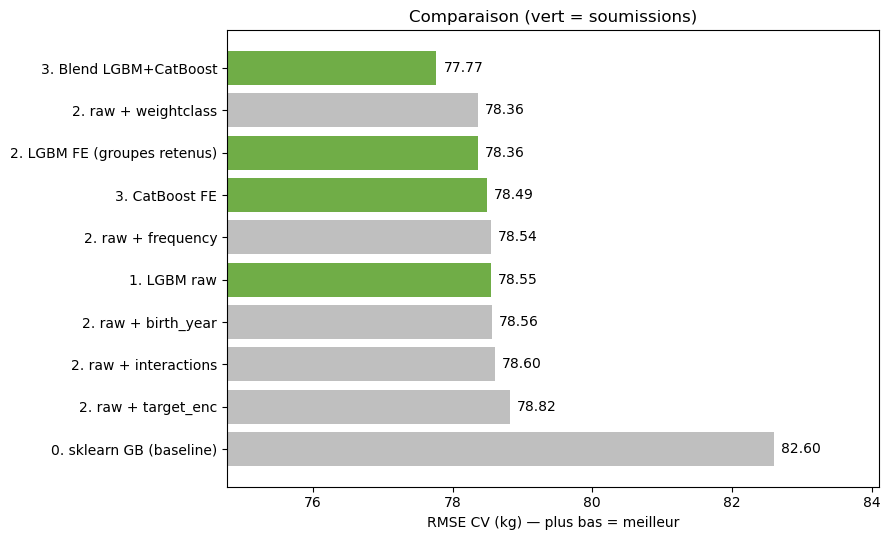

In [9]:
summary = pd.Series({'0. sklearn GB (baseline)': 82.60, **{k: v[2] for k, v in results.items()}}).sort_values()
print(summary.round(3))

fig, ax = plt.subplots(figsize=(9, 0.45 * len(summary) + 1))
colors = ['#70AD47' if k.startswith(('1.', '3.')) or k == '2. LGBM FE (groupes retenus)' else '#BFBFBF'
          for k in summary.index]
ax.barh(summary.index, summary.values, color=colors)
for i, v in enumerate(summary.values):
    ax.text(v + 0.1, i, f'{v:.2f}', va='center')
ax.set_xlim(summary.min() - 3, summary.max() + 1.5)
ax.set_xlabel('RMSE CV (kg) — plus bas = meilleur')
ax.set_title('Comparaison (vert = soumissions)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()